# Cadence CNN training

Trains the windowed CNN in `laptop/model.py` on 4 s windows of raw 6-axis IMU
data. Labels are cadence (steps/s) from the stride times in `data/strides.csv`
through `laptop/cadence.py`. The loss is Gaussian NLL, so the model predicts
cadence ± σ.

1. Load recordings and cut windows
2. Train function
3. Leave one recording out
4. Held-out plots
5. Final model and export
6. numpy vs torch check

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, "..")
from cadence import cadence, phase_knots
from model import (CHANNELS, FS, STILL_SIGMA, WIN, CadenceCNN, export, forward_np,
                   gaussian_nll, is_still, load)

DATA_DIR = Path("../../data")
OUT = Path("../../python/cnn.json")
HOP = 25        # samples between windows (0.5 s)
EPOCHS = 60
WARMUP = 10     # epochs of MSE on the mean before switching to NLL
BATCH = 64
GAIN = 0.1      # +- per-channel gain augmentation
NOISE = 0.05    # augmentation noise std, in normalized units

## 1. Load and cut windows

In [2]:
steps = pd.read_csv(DATA_DIR / "steps.csv").set_index("file").steps
strides = pd.read_csv(DATA_DIR / "strides.csv")


def windows(df, s):
    """Windows every HOP samples: X (n, WIN, 6), cadence y (n,), window end times (n,) in s."""
    t = (df.t_ms.values - df.t_ms.values[0]) / 1000.0
    starts = np.arange(0, len(df) - WIN + 1, HOP)
    X = np.stack([df[CHANNELS].values[i:i + WIN] for i in starts]).astype(np.float32)
    y = cadence(t[starts], t[starts + WIN - 1], phase_knots(s)).astype(np.float32)
    return X, y, t[starts + WIN - 1]


data = {}
for p in sorted(DATA_DIR.glob("*_*.csv")):
    df = pd.read_csv(p)
    s = (strides[strides.file == p.name].t_ms.values - df.t_ms.iloc[0]) / 1000.0
    data[p.name] = windows(df, s)
walks = [f for f in data if f.startswith("walk")]

pd.DataFrame({"windows": {f: len(d[1]) for f, d in data.items()}, "N": steps})

,windows,N
still_01.csv,161,0
still_02.csv,118,0
walk_01.csv,251,225
walk_02.csv,254,210
walk_03.csv,71,62
walk_04.csv,279,250
walk_05.csv,248,236
walk_06.csv,78,56
walk_07.csv,319,186


## 2. Train function

Still windows (`is_still`, a gyro threshold) are dropped, so the CNN only learns
walking cadence, and `predict` sets them to 0 ± STILL_SIGMA. Normalization comes
from the training files only. Gain augmentation is applied to the raw data,
noise after normalizing.

In [3]:
def train(files, seed=0):
    torch.manual_seed(seed)
    X = np.concatenate([data[f][0] for f in files])
    y = np.concatenate([data[f][1] for f in files])
    moving = ~np.array([is_still(x) for x in X])
    X, y = X[moving], torch.tensor(y[moving])
    mean = X.reshape(-1, 6).mean(0).astype(np.float32)
    std = X.reshape(-1, 6).std(0).astype(np.float32)
    Xr = torch.tensor(X).permute(0, 2, 1)                      # (n, 6, WIN)
    m, sd = torch.tensor(mean)[:, None], torch.tensor(std)[:, None]

    model = CadenceCNN()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    for epoch in range(EPOCHS):
        for idx in torch.randperm(len(y)).split(BATCH):
            gain = 1 + GAIN * (2 * torch.rand(len(idx), 6, 1) - 1)
            xb = (Xr[idx] * gain - m) / sd
            xb = xb + NOISE * torch.randn_like(xb)
            mu, logvar = model(xb)
            if epoch < WARMUP:
                loss = ((mu - y[idx]) ** 2).mean()
            else:
                loss = gaussian_nll(mu, logvar, y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return model.eval(), mean, std


def predict(model, mean, std, X):
    """Cadence mean and σ for windows X (n, WIN, 6). Still windows get 0 ± STILL_SIGMA."""
    with torch.no_grad():
        mu, logvar = model(torch.tensor((X - mean) / std).permute(0, 2, 1))
    mu, sd = mu.numpy(), np.exp(0.5 * logvar.numpy())
    still = np.array([is_still(x) for x in X])
    mu[still], sd[still] = 0.0, STILL_SIGMA
    return mu, sd


def count(c):
    """Steps from window cadences: the first window covers WIN, each later one adds HOP."""
    return (c[0] * WIN + c[1:].sum() * HOP) / FS

## 3. Leave one recording out

Each fold trains on the other 6 walks and tests on the held-out walk and
still_02. If σ is calibrated, about 68% of windows fall within 1σ and
95% within 2σ. "label count" is the same count formula applied to the labels,
so its gap to N is the error from the formula itself.

In [4]:
rows, preds = [], {}
for f in walks:
    model, mean, std = train([w for w in walks if w != f])
    X, y, t = data[f]
    mu, sd = predict(model, mean, std, X)
    preds[f] = (t, y, mu, sd)
    err = np.abs(mu - y)
    mu_still, _ = predict(model, mean, std, data["still_02.csv"][0])
    rows.append({
        "held out": f,
        "MAE": err.mean(),
        "in 1σ": (err < sd).mean(),
        "in 2σ": (err < 2 * sd).mean(),
        "mean σ": sd.mean(),
        "still windows": int(sum(is_still(x) for x in X)),
        "count": count(mu),
        "label count": count(y),
        "N": steps[f],
        "still_02 count": count(mu_still),
    })

cv = pd.DataFrame(rows).set_index("held out")
cv["count err"] = cv["count"] - cv.N
cv.round(3)

,MAE,in 1σ,in 2σ,mean σ,still windows,count,label count,N,still_02 count,count err
held out,,,,,,,,,,
walk_01.csv,0.028,0.845,1.000,0.052,0,227.764999,225.783005,225,0.0,2.765
walk_02.csv,0.024,0.902,0.988,0.046,0,213.296005,211.979996,210,0.0,3.296
walk_03.csv,0.026,0.761,0.986,0.040,0,61.191002,62.118000,62,0.0,-0.809
walk_04.csv,0.027,0.753,0.939,0.037,0,251.740997,251.914001,250,0.0,1.741
walk_05.csv,0.018,0.867,0.996,0.033,0,235.940002,235.977005,236,0.0,-0.060
walk_06.csv,0.052,0.705,1.000,0.066,0,53.245998,55.521000,56,0.0,-2.754
walk_07.csv,0.148,0.141,0.596,0.075,16,208.897995,186.011002,186,0.0,22.898


In [5]:
err = np.concatenate([np.abs(p[2] - p[1]) for p in preds.values()])
sd = np.concatenate([p[3] for p in preds.values()])
print(f"all held-out windows: MAE {err.mean():.3f} steps/s, "
      f"in 1σ {(err < sd).mean():.0%}, in 2σ {(err < 2 * sd).mean():.0%}")
print(f"total count err {cv['count err'].sum():.0f} of {cv.N.sum()} steps")

all held-out windows: MAE 0.052 steps/s, in 1σ 68%, in 2σ 90%
total count err 27 of 1225 steps


## 4. Held-out plots

Label vs predicted cadence ± σ, at each window's end time.

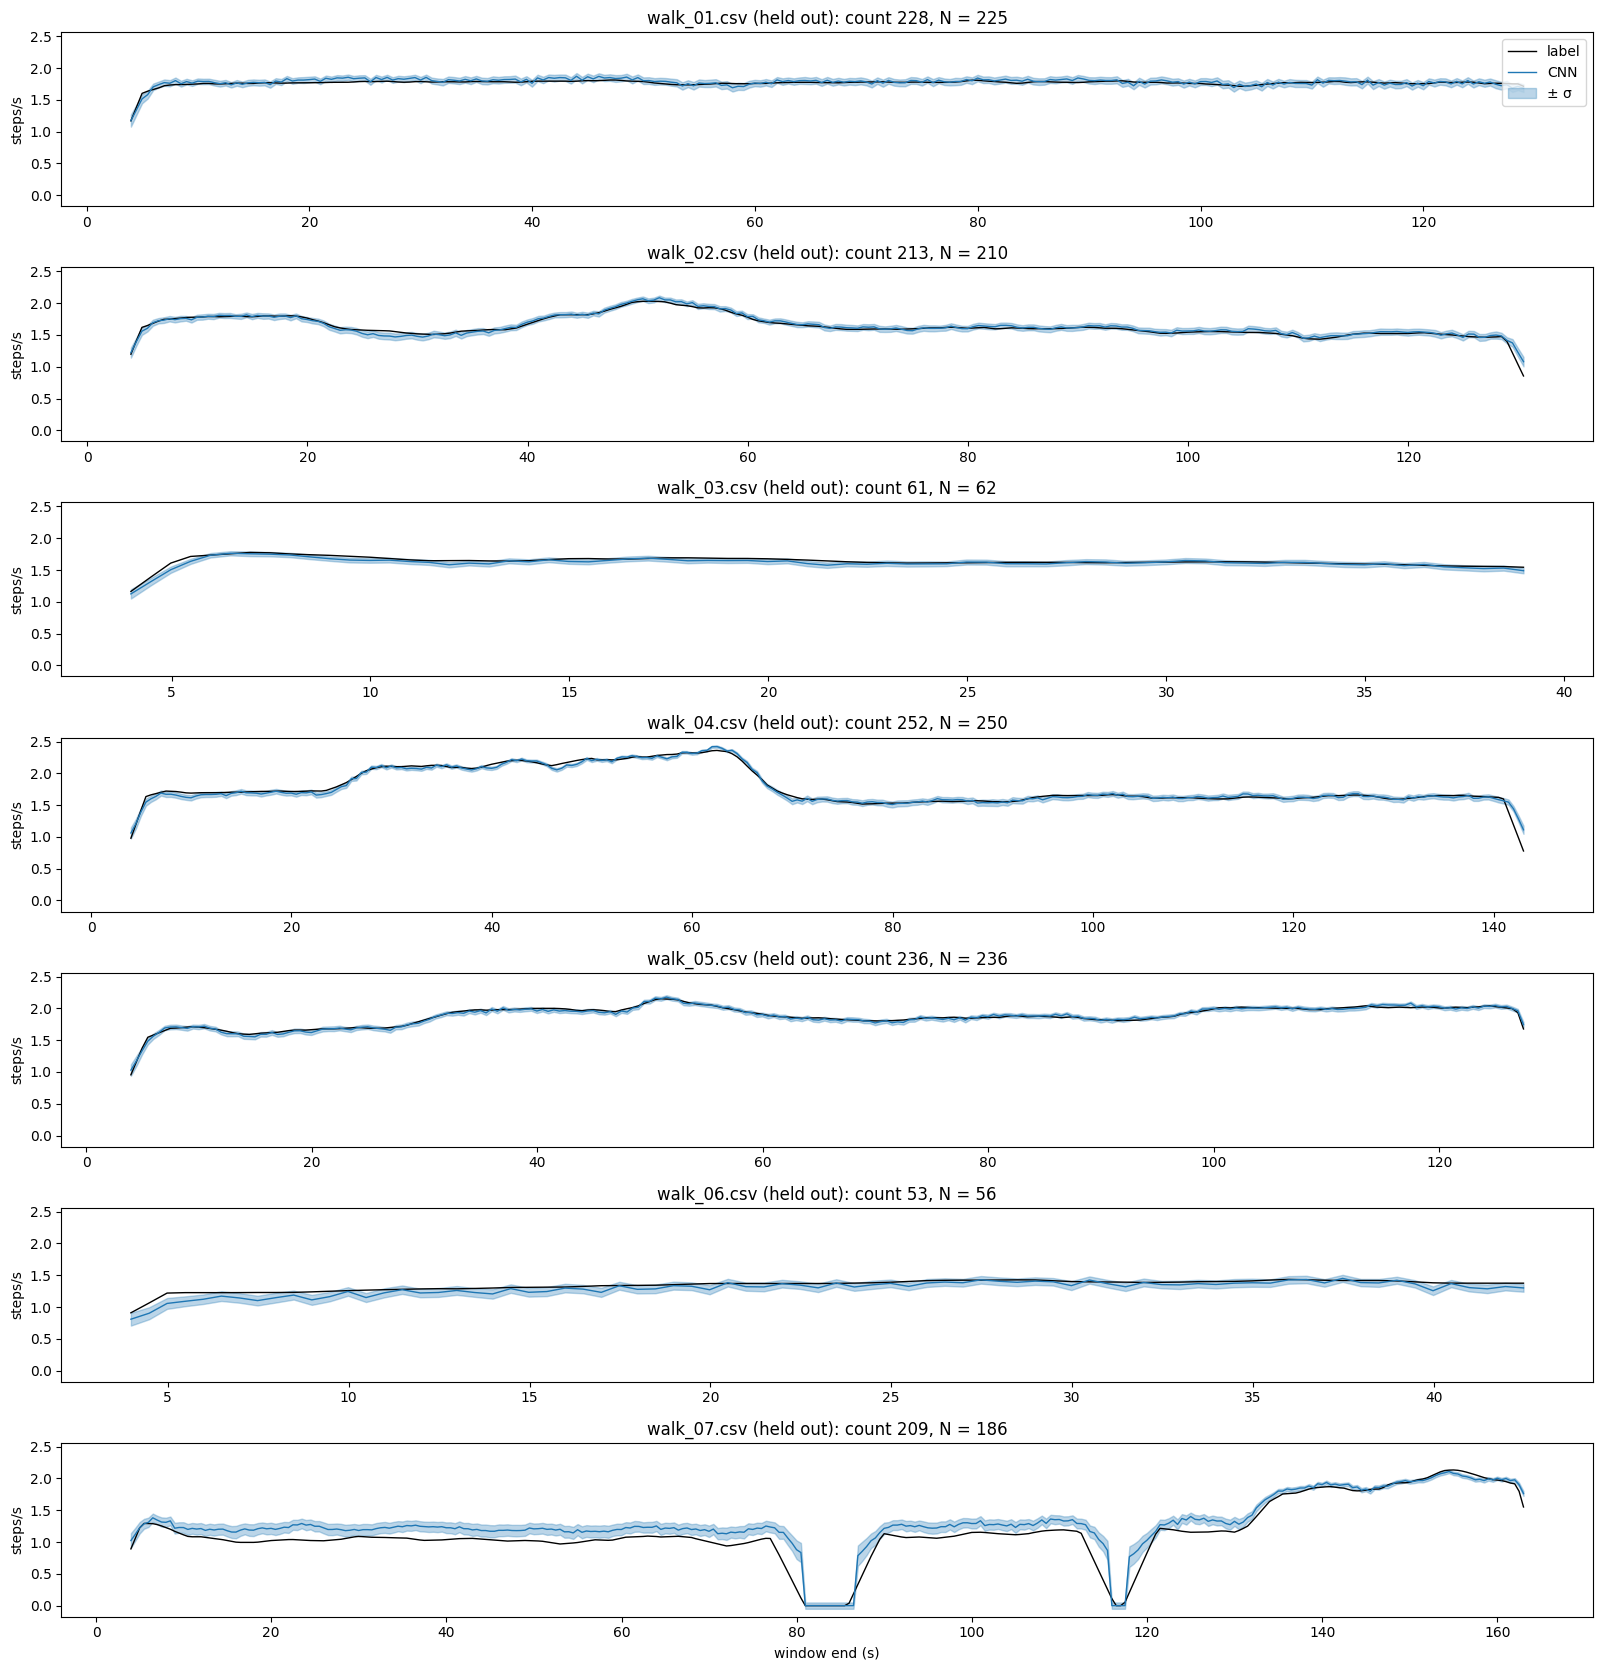

In [6]:
fig, axs = plt.subplots(len(walks), 1, figsize=(16, 2.4 * len(walks)), sharey=True)
for ax, (f, (t, y, mu, sd)) in zip(axs, preds.items()):
    ax.plot(t, y, color="k", lw=1, label="label")
    ax.plot(t, mu, color="C0", lw=1, label="CNN")
    ax.fill_between(t, mu - sd, mu + sd, color="C0", alpha=0.3, label="± σ")
    ax.set_title(f"{f} (held out): count {cv.loc[f, 'count']:.0f}, N = {steps[f]}")
    ax.set_ylabel("steps/s")
axs[0].legend(loc="upper right")
axs[-1].set_xlabel("window end (s)")
fig.tight_layout()

## 5. Final model and export

Trained on every recording, written to `python/cnn.json` for the board.

In [7]:
model, mean, std = train(list(data))
export(model, mean, std, OUT)
print(f"saved {OUT} ({OUT.stat().st_size / 1000:.0f} kB)")

saved ../../python/cnn.json (259 kB)


## 6. numpy vs torch check

`forward_np` is what the board runs. It should match torch to about 1e-5.

In [8]:
params = load(OUT)
X = np.concatenate([data[f][0][::10] for f in data])
with torch.no_grad():
    mu_t, lv_t = model(torch.tensor((X - mean) / std).permute(0, 2, 1))
np_out = np.array([forward_np(params, x) for x in X])
print(f"{len(X)} windows, max diff: mean {np.abs(np_out[:, 0] - mu_t.numpy()).max():.2e}, "
      f"logvar {np.abs(np_out[:, 1] - lv_t.numpy()).max():.2e}")

182 windows, max diff: mean 1.83e-07, logvar 8.64e-07
